# Задание 4. Предсказание года выпуска песни

По числовым признакам композиции необходимо предсказать год её выпуска. Это задача регрессии. Используется только предоставленный поднабор данных соревнования Kaggle. Внешние данные и ансамбли не применяются.

Рассматривается полносвязная сеть с GELU, LayerNorm и Dropout. Сравниваются встроенный AdamW и собственная реализация из задания 3. Для оценки используются MAE и RMSE в годах на отложенной выборке. Официальная метрика Kaggle может отличаться.

Данные должны находиться в `04_kaggle/data/`:

- `train_x.csv` — обучающие признаки;
- `train_y.csv` — ответы для обучения;
- `test_x.csv` — тестовые признаки.

Образец `sample_submission.csv` не обязателен. Если он есть, будет использован его формат. Без образца создаётся CSV с одним столбцом предсказаний; имя этого столбца необходимо сверить с требованиями соревнования перед загрузкой.


In [1]:
import copy
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
BATCH_SIZE = 1024
MAX_EPOCHS = 35
PATIENCE = 7
MAX_TRAIN_ROWS = 100000
VALIDATION_FRACTION = 0.2
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

TARGET_COLUMN = None
PREDICTION_COLUMN = None
SUBMISSION_ID_COLUMN = None

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
print("Устройство:", DEVICE)

Устройство: cpu


## 1. Загрузка и проверка данных

Признаки и ответы хранятся отдельно: порядок строк в `train_x.csv` и `train_y.csv` должен совпадать. При чтении проверяется количество наблюдений и наличие числовых признаков. Пути определяются относительно расположения проекта, поэтому запуск возможен как из VS Code, так и из Jupyter.


In [2]:
WINDOWS_DATA_DIR = Path(r"C:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\data")
CANDIDATES = [
    Path.cwd() / "data",
    Path.cwd() / "04_kaggle" / "data",
    Path.cwd() / "homeworks" / "04_kaggle" / "data",
    Path.cwd().parent / "04_kaggle" / "data",
    Path.cwd().parent / "homeworks" / "04_kaggle" / "data",
    WINDOWS_DATA_DIR,
]
DATA_DIR = next((path for path in CANDIDATES if (path / "train_x.csv").is_file()), WINDOWS_DATA_DIR)
required_files = ["train_x.csv", "train_y.csv", "test_x.csv"]
missing_files = [filename for filename in required_files if not (DATA_DIR / filename).is_file()]
if missing_files:
    raise FileNotFoundError(f"Не найдены файлы {missing_files} в папке {DATA_DIR}")


def read_competition_csv(path):
    frame = pd.read_csv(path)
    header_values = pd.to_numeric(pd.Index(frame.columns), errors="coerce")
    numeric_header = np.isfinite(np.asarray(header_values, dtype=float)).mean() >= 0.9
    index_header = numeric_header and np.array_equal(
        header_values, np.arange(len(frame.columns), dtype=float)
    )
    if numeric_header and not index_header:
        return pd.read_csv(path, header=None)
    return frame


def discard_exported_index(frame):
    for column in list(frame.columns):
        if not str(column).lower().startswith("unnamed:"):
            continue
        values = pd.to_numeric(frame[column], errors="coerce").to_numpy()
        if np.array_equal(values, np.arange(len(frame), dtype=float)):
            frame = frame.drop(columns=column)
    return frame


train_x_frame = discard_exported_index(read_competition_csv(DATA_DIR / "train_x.csv"))
train_y_frame = discard_exported_index(read_competition_csv(DATA_DIR / "train_y.csv"))
test_frame = discard_exported_index(read_competition_csv(DATA_DIR / "test_x.csv"))

if len(train_x_frame) != len(train_y_frame):
    y_no_header = pd.read_csv(DATA_DIR / "train_y.csv", header=None)
    if len(train_x_frame) == len(y_no_header):
        train_y_frame = y_no_header
    else:
        raise ValueError(
            f"Количество строк не совпадает: train_x={len(train_x_frame)}, "
            f"train_y={len(train_y_frame)}. Проверьте, есть ли заголовки у файлов."
        )

sample_path = DATA_DIR / "sample_submission.csv"
sample_submission = pd.read_csv(sample_path) if sample_path.is_file() else None

print("Папка:", DATA_DIR)
print("train_x:", train_x_frame.shape, "train_y:", train_y_frame.shape, "test_x:", test_frame.shape)
print("Колонки train_x:", list(train_x_frame.columns)[:12])
print("Колонки train_y:", list(train_y_frame.columns))
print("Колонки test_x:", list(test_frame.columns)[:12])
if sample_submission is not None:
    print("Образец submission:", sample_submission.shape, list(sample_submission.columns))
display(train_x_frame.head(3))
display(train_y_frame.head(3))


Папка: c:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\data
train_x: (14001, 91) train_y: (14001, 2) test_x: (6001, 91)
Колонки train_x: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Колонки train_y: [0, 1]
Колонки test_x: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,NaN,0.00000,1.00000,2.00000,3.00000,4.00000,5.00000,6.00000,7.00000,8.00000,...,80.00000,81.00000,82.00000,83.00000,84.00000,85.00000,86.0000,87.00000,88.00000,89.00000
1,133081.0,37.47518,-14.34414,40.54872,-9.10171,16.77175,-17.77113,-16.50156,-4.09543,2.49723,...,104.03557,-115.62803,-13.79660,31.60436,28.95927,-25.93164,67.6467,-25.76691,-81.90373,-61.48682
2,111484.0,48.17393,-7.02208,-30.36086,-2.41924,2.15406,-8.44502,-1.68191,-8.71434,-7.83802,...,11.58664,24.58950,-36.95682,0.73922,-0.06330,53.75838,-81.0533,8.42811,12.08694,-1.91676


,0,1
0,NaN,year
1,133081.0,2001
2,111484.0,2006


In [3]:
target_names = {"year", "release_year", "target", "label", "y", "yearprediction"}
if TARGET_COLUMN is not None:
    if TARGET_COLUMN not in train_y_frame.columns:
        raise ValueError(f"Не найдена целевая колонка {TARGET_COLUMN!r}")
    source_target = TARGET_COLUMN
else:
    target_candidates = [column for column in train_y_frame.columns
                         if str(column).strip().lower() in target_names]
    source_target = target_candidates[0] if target_candidates else train_y_frame.columns[-1]

raw_target = pd.to_numeric(train_y_frame[source_target], errors="coerce")
if raw_target.notna().mean() < 0.95:
    raise ValueError("Ответы в train_y.csv должны быть числовыми годами выпуска")

train_feature_columns = list(train_x_frame.columns)
test_feature_columns = list(test_frame.columns)
if train_feature_columns == test_feature_columns:
    feature_pairs = [(column, column) for column in train_feature_columns]
elif len(train_feature_columns) == len(test_feature_columns):
    feature_pairs = list(zip(train_feature_columns, test_feature_columns))
    print("Названия колонок различаются; признаки сопоставлены по позиции.")
else:
    raise ValueError(
        f"Число колонок в train_x ({len(train_feature_columns)}) и test_x "
        f"({len(test_feature_columns)}) различается"
    )

features = []
for train_column, test_column in feature_pairs:
    if str(train_column).lower() in {"id", "index", "row_id", "track_id", "song_id"}:
        continue
    training_values = pd.to_numeric(train_x_frame[train_column], errors="coerce")
    testing_values = pd.to_numeric(test_frame[test_column], errors="coerce")
    if training_values.notna().mean() >= 0.8 and testing_values.notna().mean() >= 0.8:
        features.append((train_column, test_column))
if not features:
    raise ValueError("Не найдено общих числовых признаков для обучения")

train_frame = pd.DataFrame({f"feature_{i}": pd.to_numeric(train_x_frame[a], errors="coerce")
                            for i, (a, _) in enumerate(features)})
test_frame = pd.DataFrame({f"feature_{i}": pd.to_numeric(test_frame[b], errors="coerce")
                           for i, (_, b) in enumerate(features)})
TARGET = "__target_year__"
train_frame[TARGET] = raw_target.to_numpy()
features = [column for column in train_frame.columns if column != TARGET]

source_name = str(source_target)
if PREDICTION_COLUMN is not None:
    PREDICTION = PREDICTION_COLUMN
elif sample_submission is not None:
    non_id_columns = [column for column in sample_submission.columns
                      if str(column).lower() not in {"id", "index", "row_id", "song_id", "track_id"}]
    if len(non_id_columns) != 1:
        raise ValueError("Неясен столбец предсказаний в шаблоне. Укажите PREDICTION_COLUMN")
    PREDICTION = non_id_columns[0]
else:
    PREDICTION = source_name if source_name.lower() not in {"0", "unnamed: 0"} else "year"
    print("Шаблона submission нет. Создадим один столбец", repr(PREDICTION),
          "— проверьте формат на странице соревнования.")

if sample_submission is not None and len(sample_submission) != len(test_frame):
    raise ValueError("Количество строк в sample_submission не совпадает с test_x")

print("Число признаков:", len(features))
print("Колонка предсказаний:", PREDICTION)
print("Число обучающих объектов:", len(train_frame))


Шаблона submission нет. Создадим один столбец '1' — проверьте формат на странице соревнования.
Число признаков: 91
Колонка предсказаний: 1
Число обучающих объектов: 14001


## 2. Разделение и предобработка

Данные делятся на обучающую (80%) и проверочную (20%) части. Медианы для пропусков, средние и стандартные отклонения рассчитываются **только по обучающей части**. Это исключает утечку информации из валидации. Признаки после стандартизации ограничиваются по модулю десятью для устойчивости к редким выбросам. Целевая переменная также стандартизируется; при оценке ошибки прогноз переводится обратно в годы.

Параметр `MAX_TRAIN_ROWS` ограничивает число наблюдений для разумного времени обучения на обычном компьютере. Для полного эксперимента его можно заменить на `None`.

In [4]:
all_features = train_frame[features].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
all_target = pd.to_numeric(train_frame[TARGET], errors="coerce").to_numpy(dtype=np.float32)
test_features = test_frame[features].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)

valid_targets = np.isfinite(all_target)
all_features = all_features[valid_targets]
all_target = all_target[valid_targets]

rng = np.random.default_rng(SEED)
selection = rng.permutation(len(all_target))
if MAX_TRAIN_ROWS is not None:
    selection = selection[:min(MAX_TRAIN_ROWS, len(selection))]
all_features = all_features[selection]
all_target = all_target[selection]

cutoff = max(1, min(len(all_target) - 1, int(len(all_target) * (1 - VALIDATION_FRACTION))))
assert len(all_target) >= 3, "Недостаточно обучающих строк"
train_indices = np.arange(cutoff)
valid_indices = np.arange(cutoff, len(all_target))

class FeatureScaler:
    def fit(self, values):
        values = np.where(np.isfinite(values), values, np.nan)
        self.median = np.nanmedian(values, axis=0)
        self.median = np.nan_to_num(self.median, nan=0.0)
        filled = np.where(np.isfinite(values), values, self.median)
        self.mean = filled.mean(axis=0)
        self.std = filled.std(axis=0)
        self.std = np.where(self.std < 1e-6, 1.0, self.std)
        return self

    def transform(self, values):
        values = np.where(np.isfinite(values), values, self.median)
        return np.clip((values - self.mean) / self.std, -10, 10).astype(np.float32)

scaler = FeatureScaler().fit(all_features[train_indices])
x_train = scaler.transform(all_features[train_indices])
x_valid = scaler.transform(all_features[valid_indices])
y_train_real = all_target[train_indices]
y_valid_real = all_target[valid_indices]
y_mean = float(y_train_real.mean())
y_std = max(float(y_train_real.std()), 1.0)
y_train = ((y_train_real - y_mean) / y_std).astype(np.float32)
y_valid = ((y_valid_real - y_mean) / y_std).astype(np.float32)

train_dataset = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
valid_dataset = TensorDataset(torch.from_numpy(x_valid), torch.from_numpy(y_valid))
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_dataset):,}, validation: {len(valid_dataset):,}, признаки: {x_train.shape[1]}")
print(f"Год: среднее {y_mean:.2f}, стандартное отклонение {y_std:.2f}")

Train: 11,200, validation: 2,800, признаки: 91
Год: среднее 1998.38, стандартное отклонение 11.07


## 3. Архитектура и оптимизаторы

Используется полносвязная нейросеть с двумя скрытыми блоками по 256 и 128 нейронов, нормализацией `LayerNorm`, нелинейностью `GELU` и регуляризацией `Dropout(0.1)`. Финальный слой возвращает одно действительное число.

Ниже приведена самостоятельная реализация AdamW (такой же алгоритм, как в третьем задании). Для неё не используется `torch.optim.AdamW`.

In [5]:
class YearRegressor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(128, 64), nn.GELU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.layers(x).squeeze(-1)

class CustomAdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        self.params = [p for p in params if p.requires_grad]
        self.lr, self.betas, self.eps, self.weight_decay = lr, betas, eps, weight_decay
        self.state = {}

    @torch.no_grad()
    def step(self):
        beta1, beta2 = self.betas
        for param in self.params:
            if param.grad is None:
                continue
            grad = param.grad
            if param not in self.state:
                self.state[param] = [0, torch.zeros_like(param), torch.zeros_like(param)]
            state = self.state[param]
            state[0] += 1
            step, mean, variance = state
            mean.mul_(beta1).add_(grad, alpha=1 - beta1)
            variance.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
            param.mul_(1 - self.lr * self.weight_decay)
            corrected_mean = mean / (1 - beta1 ** step)
            corrected_variance = variance / (1 - beta2 ** step)
            param.addcdiv_(corrected_mean, corrected_variance.sqrt().add(self.eps), value=-self.lr)

    def zero_grad(self, set_to_none=True):
        for param in self.params:
            if set_to_none:
                param.grad = None
            elif param.grad is not None:
                param.grad.zero_()

OPTIMIZER_FACTORIES = {
    "AdamW (torch)": lambda params: torch.optim.AdamW(params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
    "AdamW (custom)": lambda params: CustomAdamW(params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
}

assert YearRegressor(len(features))(torch.zeros(4, len(features))).shape == (4,)

## 4. Обучение и сравнение

Для каждого оптимизатора стартовая инициализация и порядок обучающих объектов одинаковы. На каждой эпохе считается средняя ошибка MSE при обучении, затем MAE и RMSE в годах на валидации. Лучшие параметры сохраняются в памяти. Если валидационная RMSE не улучшается в течение заданного числа эпох, обучение останавливается.

In [6]:
def metric_on_validation(model, loader, target_mean, target_std):
    model.eval()
    predictions = []
    targets = []
    with torch.inference_mode():
        for x, y in loader:
            normalized_prediction = model(x.to(DEVICE)).cpu().numpy()
            predictions.append(normalized_prediction * target_std + target_mean)
            targets.append(y.numpy() * target_std + target_mean)
    pred = np.concatenate(predictions)
    target = np.concatenate(targets)
    mae = float(np.mean(np.abs(pred - target)))
    rmse = float(np.sqrt(np.mean((pred - target) ** 2)))
    return mae, rmse, pred, target

def experiment(optimizer_name, optimizer_factory):
    torch.manual_seed(SEED)
    model = YearRegressor(len(features)).to(DEVICE)
    optimizer = optimizer_factory(model.parameters())
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    best_rmse = float("inf")
    best_epoch = 0
    best_weights = None
    no_improvement = 0
    rows = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_mse, total_count = 0.0, 0
        for x, target in loader:
            x, target = x.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad()
            loss = F.mse_loss(model(x), target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_mse += loss.item() * len(target)
            total_count += len(target)
        val_mae, val_rmse, _, _ = metric_on_validation(model, valid_loader, y_mean, y_std)
        rows.append({"optimizer": optimizer_name, "epoch": epoch,
                     "train_mse_normalized": total_mse / total_count,
                     "val_mae_years": val_mae, "val_rmse_years": val_rmse})
        if val_rmse < best_rmse - 1e-4:
            best_rmse = val_rmse
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1
        if epoch == 1 or epoch % 5 == 0 or no_improvement >= PATIENCE:
            print(f"{optimizer_name}: эпоха {epoch}, RMSE={val_rmse:.3f}, MAE={val_mae:.3f}")
        if no_improvement >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    return {"history": rows, "model": model, "best_epoch": best_epoch,
            "best_rmse": best_rmse, "best_weights": best_weights}

experiments = {}
for name, factory in OPTIMIZER_FACTORIES.items():
    experiments[name] = experiment(name, factory)

history = pd.DataFrame([row for item in experiments.values() for row in item["history"]])
summary = pd.DataFrame([
    {"optimizer": name, "best_epoch": item["best_epoch"], "val_rmse_years": item["best_rmse"]}
    for name, item in experiments.items()
]).sort_values("val_rmse_years")
display(summary.round(4))

AdamW (torch): эпоха 1, RMSE=9.854, MAE=7.219
AdamW (torch): эпоха 5, RMSE=9.377, MAE=6.609
AdamW (torch): эпоха 10, RMSE=9.570, MAE=6.548
AdamW (torch): эпоха 13, RMSE=9.714, MAE=6.709
AdamW (custom): эпоха 1, RMSE=9.854, MAE=7.219
AdamW (custom): эпоха 5, RMSE=9.377, MAE=6.609
AdamW (custom): эпоха 10, RMSE=9.570, MAE=6.548
AdamW (custom): эпоха 13, RMSE=9.714, MAE=6.709


,optimizer,best_epoch,val_rmse_years
0,AdamW (torch),6,9.3081
1,AdamW (custom),6,9.3081


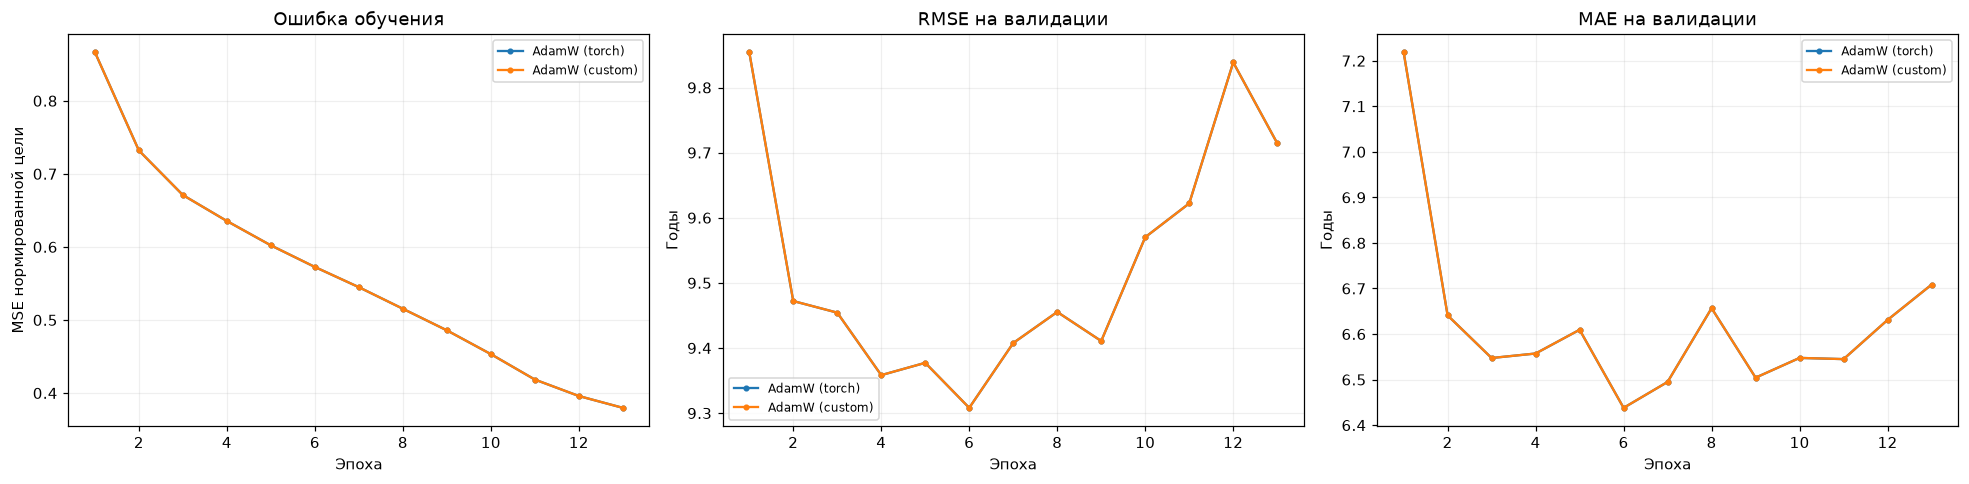

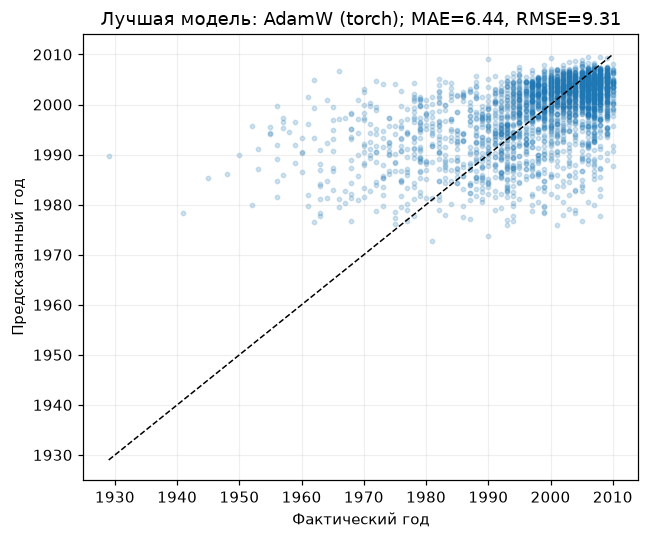

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in OPTIMIZER_FACTORIES:
    part = history[history.optimizer == name]
    axes[0].plot(part.epoch, part.train_mse_normalized, marker=".", label=name)
    axes[1].plot(part.epoch, part.val_rmse_years, marker=".", label=name)
    axes[2].plot(part.epoch, part.val_mae_years, marker=".", label=name)
for axis, title, ylabel in zip(axes,
    ["Ошибка обучения", "RMSE на валидации", "MAE на валидации"],
    ["MSE нормированной цели", "Годы", "Годы"]):
    axis.set_title(title)
    axis.set_xlabel("Эпоха")
    axis.set_ylabel(ylabel)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_name = summary.iloc[0]["optimizer"]
best_model = experiments[best_name]["model"]
mae, rmse, predicted, actual = metric_on_validation(best_model, valid_loader, y_mean, y_std)
fig, axis = plt.subplots(figsize=(6, 5))
axis.scatter(actual, predicted, s=8, alpha=0.2)
bounds = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axis.plot(bounds, bounds, linestyle="--", color="black", linewidth=1)
axis.set_xlabel("Фактический год")
axis.set_ylabel("Предсказанный год")
axis.set_title(f"Лучшая модель: {best_name}; MAE={mae:.2f}, RMSE={rmse:.2f}")
plt.tight_layout()
plt.show()

## 5. Обучение итоговой модели на всех доступных обучающих данных

После выбора оптимизатора по валидации выбранная архитектура обучается заново на объединённой обучающей и проверочной частях. Число эпох задаётся лучшей эпохой отложенной валидации. Все параметры стандартизации переоцениваются только по исходному обучающему файлу, без тестовых ответов.

Получается **одна** итоговая модель. Предсказания не усредняются с другими моделями.

In [8]:
final_scaler = FeatureScaler().fit(all_features)
x_full = final_scaler.transform(all_features)
x_test = final_scaler.transform(test_features)
final_target_mean = float(all_target.mean())
final_target_std = max(float(all_target.std()), 1.0)
y_full = ((all_target - final_target_mean) / final_target_std).astype(np.float32)

full_dataset = TensorDataset(torch.from_numpy(x_full), torch.from_numpy(y_full))
full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED), num_workers=0)

torch.manual_seed(SEED)
final_model = YearRegressor(len(features)).to(DEVICE)
final_optimizer = OPTIMIZER_FACTORIES[best_name](final_model.parameters())
final_epochs = int(experiments[best_name]["best_epoch"])
for epoch in range(1, final_epochs + 1):
    final_model.train()
    for x, target in full_loader:
        x, target = x.to(DEVICE), target.to(DEVICE)
        final_optimizer.zero_grad()
        loss = F.mse_loss(final_model(x), target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=5.0)
        final_optimizer.step()

final_model.eval()
test_loader = DataLoader(torch.from_numpy(x_test), batch_size=BATCH_SIZE)
test_predictions = []
with torch.inference_mode():
    for x in test_loader:
        prediction = final_model(x.to(DEVICE)).cpu().numpy()
        test_predictions.append(prediction * final_target_std + final_target_mean)
test_predictions = np.concatenate(test_predictions)
assert len(test_predictions) == len(test_frame)
assert np.isfinite(test_predictions).all()
print(f"Итог: {best_name}, эпох: {final_epochs}, тестовых прогнозов: {len(test_predictions)}")

Итог: AdamW (torch), эпох: 6, тестовых прогнозов: 6001


## 6. Подготовка submission.csv

Для загрузки на Kaggle создаётся таблица с двумя столбцами: `id` и `label`. `label` содержит прогнозы года выпуска, `id` — идентификаторы тестовых строк. Если в `sample_submission.csv` или `test_x.csv` есть поле `id`, используются его значения. Иначе создаётся последовательность от 0 до количества тестовых строк минус 1. Этот вариант следует сверить с описанием соревнования, так как из файлов без ID нельзя надёжно установить официальный способ нумерации.

Перед сохранением проверяется число строк, уникальность идентификаторов и отсутствие пропущенных значений. Округление прогноза года не выполняется.


In [10]:

predictions = np.asarray(test_predictions, dtype=np.float64).reshape(-1)

if sample_submission is not None and "id" in sample_submission.columns:
    ids = sample_submission["id"].to_numpy()
    id_source = "sample_submission.csv"
elif "id" in test_frame.columns:
    ids = test_frame["id"].to_numpy()
    id_source = "test_x.csv"
else:
    ids = np.arange(len(predictions), dtype=np.int64)
    id_source = "порядковые номера строк, начиная с 0"

submission = pd.DataFrame({
    "id": ids,
    "label": predictions
})

assert len(submission) == len(test_frame), "Число прогнозов не совпадает с числом тестовых строк"
assert submission["id"].notna().all(), "Найдены пустые id"
assert submission["id"].is_unique, "ID должны быть уникальными"
assert np.isfinite(submission["label"].to_numpy()).all(), "Есть пустые или некорректные предсказания"

SUBMISSION_PATH = DATA_DIR.parent / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

print("Файл сохранён:", SUBMISSION_PATH)
print("Источник id:", id_source)
print("Размер:", submission.shape)
print("Колонки:", submission.columns.tolist())
print("Пропуски:", submission.isna().sum().to_dict())

display(submission.head(5))


Файл сохранён: c:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\submission.csv
Источник id: порядковые номера строк, начиная с 0
Размер: (6001, 2)
Колонки: ['id', 'label']
Пропуски: {'id': 0, 'label': 0}


,id,label
0,0,1984.875122
1,1,1994.912231
2,2,2004.573120
3,3,1985.412354
4,4,2006.141968


## Выводы и ограничения

Валидационная ошибка позволяет сравнить встроенный AdamW и собственную реализацию на одной архитектуре. Близкие результаты ожидаемы, если обе версии алгоритма обновляют параметры одинаково; небольшие различия могут появиться из-за порядка операций с плавающей точкой. Итоговая модель выбирается по минимальному RMSE в годах.

Для последующего улучшения результата можно изменить число нейронов, dropout, learning rate, размер батча и число эпох. Необходимо оценивать качество на собственной валидации, не подгоняя гиперпараметры исключительно под публичный leaderboard.

**Ограничение воспроизводимости:** фактическое значение метрики, соответствие формату соревнования и успешная загрузка на Kaggle подтверждаются только после выполнения ноутбука на исходных CSV соревнования и отправки `submission.csv`.

**Источники:** [условие соревнования](https://www.kaggle.com/t/dace4caa40384c86a9879217eaccab42), [PyTorch: AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html), [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101).

Если в `test_x.csv` и `sample_submission.csv` нет столбца `id`, индекс тестовой строки используется как предположение о формате идентификаторов. Его следует сверить с требованиями соревнования.


In [15]:

test_csv = pd.read_csv(DATA_DIR / "test_x.csv")

predictions = np.asarray(test_predictions, dtype=np.float64).reshape(-1)

if len(predictions) == len(test_csv) + 1:
    predictions = predictions[1:]

assert len(predictions) == len(test_csv), "Число предсказаний не совпадает с числом строк"

id_candidates = []

for column in test_csv.columns:
    values = pd.to_numeric(test_csv[column], errors="coerce").to_numpy(dtype=np.float64)

    if (
        np.isfinite(values).all()
        and np.all(values == np.floor(values))
        and len(np.unique(values)) == len(values)
    ):
        id_candidates.append(column)

print("Возможные столбцы с ID:", id_candidates)

for column in id_candidates:
    print(f"Столбец {column}, первые значения:", test_csv[column].head(5).tolist())

if len(id_candidates) != 1:
    print("Первые и последние столбцы тестовых данных:")
    display(test_csv.iloc[:5, :3])
    display(test_csv.iloc[:5, -3:])
    raise ValueError("Не удалось однозначно определить столбец ID")

ids = test_csv[id_candidates[0]].astype(np.int64).to_numpy()
years = np.rint(predictions).astype(np.int64)

submission = pd.DataFrame({
    "id": ids,
    "label": years
})

assert len(submission) == 6000
assert submission["id"].is_unique
assert submission.notna().all().all()

SUBMISSION_PATH = DATA_DIR.parent / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

print("Файл сохранён:", SUBMISSION_PATH)
print("Размер:", submission.shape)
display(submission.head(10))


Возможные столбцы с ID: ['id']
Столбец id, первые значения: [3416, 18991, 11105, 18902, 18958]
Файл сохранён: c:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\submission.csv
Размер: (6000, 2)


,id,label
0,3416,1995
1,18991,2005
2,11105,1985
3,18902,2006
4,18958,1995
5,8132,2000
6,4442,1996
7,5562,1984
8,16836,1995
9,3555,1991
